<div align="center">

<h1> <b> FÓRMULA SEMIEMPÍRICA DE MASAS Y AJUSTE LOCAL PARA A = 131 </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Ross Miranda <br>
Cristian Vergara</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

---


## 1. Introducción

En este trabajo se emplean datos experimentales de energías de enlace nuclear para comparar la energía de enlace por nucleón, $\mathrm{BE}/A$, con la predicción de la **fórmula semiempírica de masas** (o modelo de gota líquida), y para realizar un ajuste parabólico local de la masa nuclear en la cadena isobárica $A = 131$.

La masa nuclear se describe localmente, en función del número atómico $Z$, mediante

$$
M(Z) = \alpha + \beta\,Z + \gamma\,Z^2,
$$

lo que permite estimar los valores de $Q_\beta$ (energía liberada en la desintegración $\beta^-$) y compararlos con los valores obtenidos directamente de las masas experimentales. Los cálculos numéricos se realizan con NumPy (Harris et al., 2020) y pandas, y las figuras se generan con Matplotlib (Hunter, 2007).

## 2. Lectura de Datos y Visualización Inicial

Los datos experimentales se encuentran en el archivo `mybinding.dat`, con cuatro columnas:

- $Z$: número atómico (protones).
- $A$: número de masa.
- $\mathrm{BE}_{\exp}$: energía de enlace experimental, en MeV.
- $N = A - Z$: número de neutrones.

El formato corresponde al de las evaluaciones de masas atómicas de uso estándar en física nuclear, como AME2020 (Wang et al., 2021); el archivo no indica la edición de la que se tomaron los valores.

A continuación se grafica la energía de enlace por nucleón, $\mathrm{BE}/A$, en función de $A$, $N$ y $Z$, para obtener una visión global de los datos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ruta del archivo de datos experimentales de energia de enlace nuclear.
# El archivo contiene, por columnas: Z, A, BE_exp (MeV) y N.
RUTA_DATOS = "mybinding.dat"

datos_enlace = np.loadtxt(RUTA_DATOS)

Z = datos_enlace[:, 0]
A = datos_enlace[:, 1]
BE = datos_enlace[:, 2]
N = datos_enlace[:, 3]

# Verificacion fisica basica: por definicion N = A - Z para todo nucleido,
# de modo que un desacuerdo indicaria un error en el archivo de datos o en
# el orden de las columnas, y comprometeria todos los calculos posteriores.
if not np.allclose(N, A - Z):
    raise ValueError("Inconsistencia en los datos: N no coincide con A - Z.")

print(f"Numero de nucleidos leidos: {len(Z)}")
print("Primeros 5 registros:")
for z, a, be, n in zip(Z[:5], A[:5], BE[:5], N[:5]):
    print(f"Z={z:.0f}, A={a:.0f}, BE={be:.4f} MeV, N={n:.0f}")


Numero de nucleidos leidos: 2375
Primeros 5 registros:
Z=1, A=2, BE=2.2246 MeV, N=1
Z=1, A=3, BE=8.4818 MeV, N=2
Z=1, A=4, BE=6.8818 MeV, N=3
Z=1, A=5, BE=6.6818 MeV, N=4
Z=1, A=6, BE=5.7698 MeV, N=5


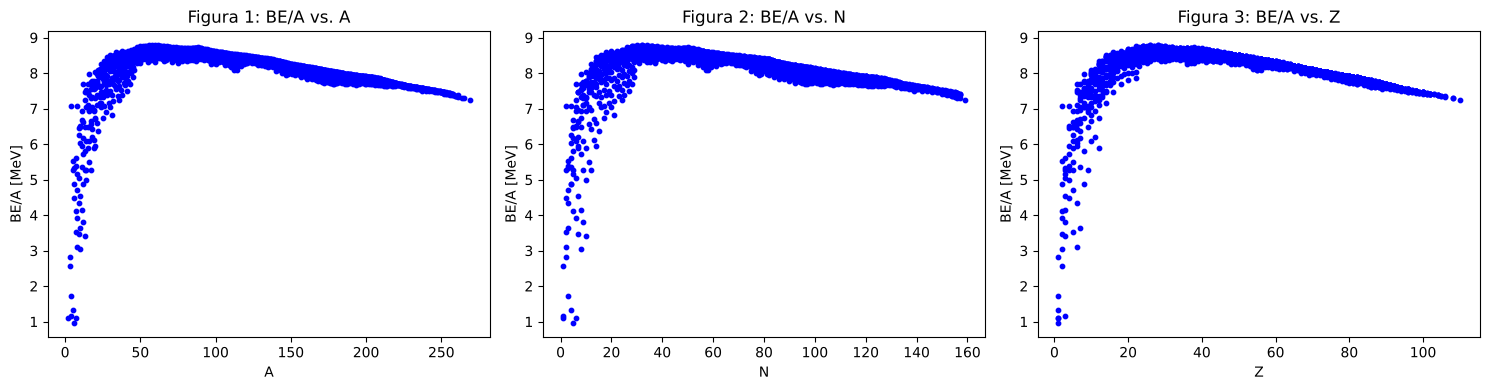

In [2]:
# Vision global de BE/A en funcion de A, N y Z.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

paneles = [
    (A, "A", "Figura 1: BE/A vs. A"),
    (N, "N", "Figura 2: BE/A vs. N"),
    (Z, "Z", "Figura 3: BE/A vs. Z"),
]

for ax, (x, xlabel, titulo) in zip(axes, paneles):
    ax.scatter(x, BE / A, color="blue", s=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("BE/A [MeV]")
    ax.set_title(titulo)

plt.tight_layout()
plt.show()


### Análisis de las Figuras 1, 2 y 3

Las tres gráficas muestran el comportamiento característico de la energía de enlace por nucleón. Al graficar $\mathrm{BE}/A$ contra $A$ (Fig. 1), se observa un incremento hasta un máximo cercano a $A \approx 60$, seguido de un descenso paulatino para núcleos más pesados. Las gráficas contra $N$ y contra $Z$ (Figs. 2 y 3) muestran la misma tendencia con el eje horizontal comprimido o estirado según la proporción de neutrones y protones, que cambia con la masa del núcleo: $N \approx Z$ en los núcleos ligeros y $N \approx 1.5\,Z$ en los más pesados.

---

## 3. Modelo de Gota Líquida: Comparación Global

La fórmula semiempírica de masas, sin incluir el término de apareamiento $\delta$, se escribe como

$$
B(A,Z) = a_1 A - a_2 A^{2/3} - a_3 \frac{Z^2}{A^{1/3}} - a_4 \frac{(N-Z)^2}{A}.
$$

Los coeficientes empleados a continuación ($a_1 = 15.48$, $a_2 = 17.23$, $a_3 = 0.697$ y $a_4 = 22.6$ MeV) corresponden a una parametrización estándar de la fórmula semiempírica sin término de apareamiento; valores de este orden se reportan de manera consistente en la literatura de física nuclear (véase, p. ej., Krane, 1988, para una introducción al modelo y sus términos). A continuación se compara la energía de enlace por nucleón experimental con la que predice el modelo, incluyendo cada término de forma acumulativa (volumen, +superficie, +Coulomb, +asimetría).

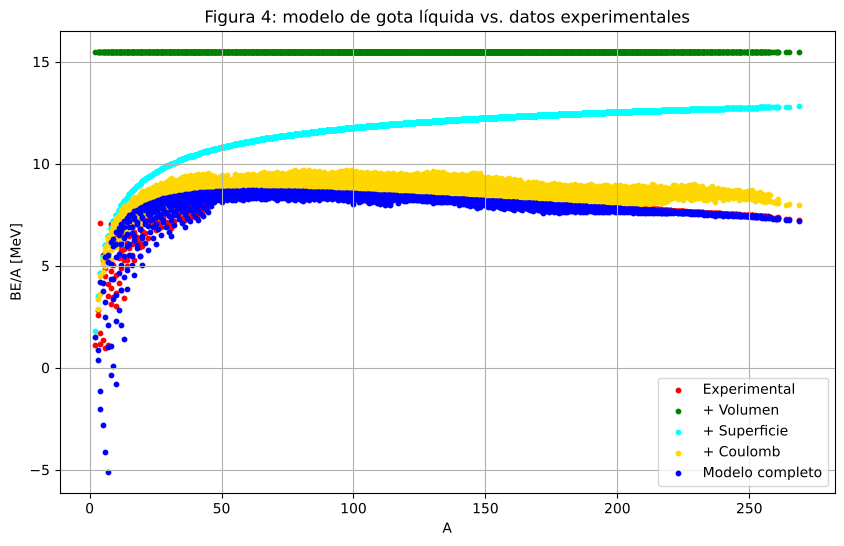

In [3]:
def BE_liquida(A, Z, N, alpha1=15.48, alpha2=17.23, alpha3=0.697, alpha4=22.6):
    """Energía de enlace total predicha por el modelo de gota líquida.

    Implementa la fórmula semiempírica de masas sin término de apareamiento:
    B(A, Z) = a1*A - a2*A^(2/3) - a3*Z^2/A^(1/3) - a4*(N-Z)^2/A.

    Parámetros
    ----------
    A, Z, N : array_like
        Número de masa, número atómico y número de neutrones.
    alpha1..alpha4 : float
        Coeficientes de volumen, superficie, Coulomb y asimetría (MeV).
        Poner en cero el coeficiente de un término lo excluye del cálculo,
        lo que permite construir las curvas acumulativas de la Figura 4.

    Retorna
    -------
    ndarray
        Energía de enlace total predicha, en MeV.
    """
    return (alpha1 * A
            - alpha2 * A**(2 / 3)
            - alpha3 * Z**2 / A**(1 / 3)
            - alpha4 * (N - Z)**2 / A)


# Modelo completo y contribuciones acumulativas de cada término: se anulan
# sucesivamente los coeficientes de superficie, Coulomb y asimetría para
# aislar el efecto de cada uno sobre BE/A.
BE_modelo_volumen = BE_liquida(A, Z, N, alpha2=0, alpha3=0, alpha4=0)
BE_modelo_sup = BE_liquida(A, Z, N, alpha3=0, alpha4=0)
BE_modelo_coulomb = BE_liquida(A, Z, N, alpha4=0)
BE_modelo = BE_liquida(A, Z, N)

plt.figure(figsize=(10, 6))
plt.scatter(A, BE / A, color="red", s=10, label="Experimental")
plt.scatter(A, BE_modelo_volumen / A, color="green", s=10, label="+ Volumen")
plt.scatter(A, BE_modelo_sup / A, color="cyan", s=10, label="+ Superficie")
plt.scatter(A, BE_modelo_coulomb / A, color="gold", s=10, label="+ Coulomb")
plt.scatter(A, BE_modelo / A, color="blue", s=10, label="Modelo completo")

plt.xlabel("A")
plt.ylabel("BE/A [MeV]")
plt.title("Figura 4: modelo de gota líquida vs. datos experimentales")
plt.legend()
plt.grid(True)
plt.show()


### Discusión de la Figura 4

La curva experimental (puntos rojos) exhibe el máximo de la energía de enlace por nucleón cerca de $A \approx 60$. El término de volumen (verde) por sí solo da una energía constante de unos 15.5 MeV por nucleón, que sobreestima la de todos los núcleos. El término de superficie (cian) reduce la energía de enlace sobre todo en los núcleos ligeros, en los que una fracción mayor de los nucleones está en la superficie, pero deja una curva que crece monótonamente con $A$. Es el término de Coulomb (amarillo), que crece como $Z^2/A^{1/3}$, el que introduce la disminución de $\mathrm{BE}/A$ en los núcleos pesados y, con ella, el máximo de la curva. Finalmente, el término de asimetría $(N-Z)^2/A$ (azul) penaliza el exceso de neutrones de los núcleos pesados y lleva el modelo completo muy cerca de los datos para $A \gtrsim 20$. En los núcleos más ligeros el modelo falla por completo, e incluso predice energías de enlace negativas: para ellos, la imagen de una gota de materia nuclear con volumen y superficie bien definidos deja de ser válida.

### 3.1. Residuos del modelo y efectos de capa

Los coeficientes de la Figura 4 son una parametrización tomada de la literatura y no un ajuste a estos datos. Como la energía de enlace es lineal en los coeficientes, se pueden ajustar por mínimos cuadrados a los núcleos con $A \geq 16$, añadiendo el término de apareamiento

$$
+\,a_5\,\frac{\delta}{A^{1/2}}, \qquad \delta = \begin{cases} +1 & Z \text{ y } N \text{ pares} \\ 0 & A \text{ impar} \\ -1 & Z \text{ y } N \text{ impares,} \end{cases}
$$

que da cuenta de la mayor estabilidad de los núcleos con protones y neutrones apareados (Krane, 1988). Los residuos $\mathrm{BE}_{\exp} - \mathrm{BE}_{\text{modelo}}$ muestran entonces lo que la gota líquida no describe.

a1 (volumen)       =  15.543 MeV
a2 (superficie)    =  16.967 MeV
a3 (Coulomb)       =   0.703 MeV
a4 (asimetría)     =  23.020 MeV
a5 (apareamiento)  =  12.071 MeV

Residuo para A >= 16 con los coeficientes de la Figura 4: media = 9.5 MeV, rms = 10.4 MeV
Residuo para A >= 16 con los coeficientes ajustados:    media = -0.0 MeV, rms = 3.0 MeV


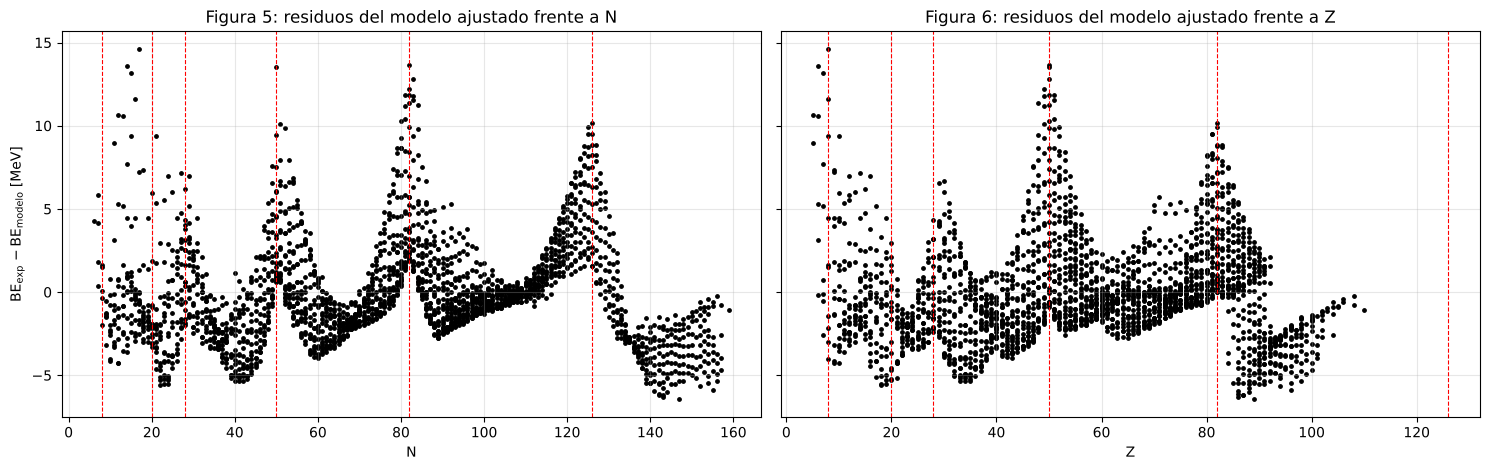

In [4]:
# Término de apareamiento: +1 par-par, 0 para A impar, -1 impar-impar
delta_apareamiento = np.where((Z % 2 == 0) & (N % 2 == 0), 1.0,
                              np.where((Z % 2 == 1) & (N % 2 == 1), -1.0, 0.0))
terminos = np.column_stack([A, -A**(2 / 3), -Z**2 / A**(1 / 3), -(N - Z)**2 / A,
                            delta_apareamiento / np.sqrt(A)])

seleccion = A >= 16
coeficientes, *_ = np.linalg.lstsq(terminos[seleccion], BE[seleccion], rcond=None)
residuo_ajuste = BE - terminos @ coeficientes
residuo_original = BE - BE_modelo

for nombre, valor in zip(["a1 (volumen)", "a2 (superficie)", "a3 (Coulomb)",
                          "a4 (asimetría)", "a5 (apareamiento)"], coeficientes):
    print(f"{nombre:<18} = {valor:7.3f} MeV")
print(f"\nResiduo para A >= 16 con los coeficientes de la Figura 4: media = "
      f"{residuo_original[seleccion].mean():.1f} MeV, rms = {np.sqrt(np.mean(residuo_original[seleccion]**2)):.1f} MeV")
print(f"Residuo para A >= 16 con los coeficientes ajustados:    media = "
      f"{residuo_ajuste[seleccion].mean():.1f} MeV, rms = {np.sqrt(np.mean(residuo_ajuste[seleccion]**2)):.1f} MeV")

MAGICOS = [8, 20, 28, 50, 82, 126]
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for eje, variable, etiqueta in [(ejes[0], N, "N"), (ejes[1], Z, "Z")]:
    eje.scatter(variable[seleccion], residuo_ajuste[seleccion], s=6, color="black")
    for numero in MAGICOS:
        eje.axvline(numero, color="red", linestyle="--", linewidth=0.8)
    eje.set_xlabel(etiqueta)
    eje.grid(True, alpha=0.3)
ejes[0].set_ylabel(r"$\mathrm{BE}_{\exp} - \mathrm{BE}_{\mathrm{modelo}}$ [MeV]")
ejes[0].set_title("Figura 5: residuos del modelo ajustado frente a N")
ejes[1].set_title("Figura 6: residuos del modelo ajustado frente a Z")
plt.tight_layout()
plt.show()

**Figuras 5 y 6**: residuos de la fórmula semiempírica con los coeficientes ajustados, frente al número de neutrones y de protones. Las líneas rojas marcan los números mágicos 8, 20, 28, 50, 82 y 126.

Con los coeficientes de la Figura 4, el modelo subestima la energía de enlace en 9.5 MeV en promedio; el ajuste reduce el residuo cuadrático medio de 10.4 MeV a 3.0 MeV, con coeficientes muy cercanos a los de la literatura. Los residuos que quedan no son ruido: forman picos agudos en $N = 28$, 50, 82 y 126 y en $Z = 28$, 50 y 82, donde los núcleos están varios MeV más ligados de lo que predice la gota líquida. Esos son los números mágicos del modelo de capas: con una capa de protones o de neutrones completa, el núcleo gana una estabilidad adicional que un modelo de fluido continuo no puede describir (Krane, 1988). Este exceso de energía de enlace reaparece en la sección 8, al analizar los isóbaros de $A = 131$ más próximos a $Z = 50$ y $N = 82$.

## 4. Ajuste Local de Masas para A = 131

Nos enfocamos ahora en los isóbaros con $A = 131$. La masa nuclear se aproxima como

$$
M(Z, A) \approx Z\,m_p + (A - Z)\,m_n - \mathrm{BE}_{\exp},
$$

con $m_p \approx 938.272$ MeV/$c^2$ y $m_n \approx 939.565$ MeV/$c^2$.

### 4.1. Cálculo de masas y filtrado para A = 131

In [5]:
# Masas de reposo del proton, el neutron y el electron, en MeV/c^2
# (CODATA 2014; Mohr, Newell, & Taylor, 2016). El electron se necesita mas
# adelante (Seccion 5) para calcular correctamente Q_beta a partir de
# diferencias de masa nuclear.
m_p = 938.2720813
m_n = 939.5654133
m_e = 0.5109989461


def masa_nuclear(Z, A, BE):
    """Masa nuclear aproximada, en MeV/c^2, a partir de la energía de enlace.

    Se calcula como la suma de las masas de los nucleones libres menos la
    energía de enlace: M(Z, A) = Z*m_p + (A-Z)*m_n - BE. Corresponde a la
    masa del núcleo desnudo, sin los electrones atómicos.
    """
    return Z * m_p + (A - Z) * m_n - BE


# Se reutilizan los datos ya leídos (Z, A, BE) para construir un DataFrame,
# lo que evita leer el archivo de datos una segunda vez.
df = pd.DataFrame({"Z": Z.astype(int), "A": A.astype(int), "BE_exp": BE})
df["mass"] = masa_nuclear(df["Z"], df["A"], df["BE_exp"])

# Filtrado de los isobaros con A = 131.
df_A131 = df[df["A"] == 131].copy().reset_index(drop=True)
print("Datos para A=131:")
print(df_A131)


Datos para A=131:
     Z    A     BE_exp           mass
0   49  131  1087.0574  121932.638474
1   50  131  1095.4969  121922.905642
2   51  131  1099.4189  121917.690310
3   52  131  1101.8716  121913.944278
4   53  131  1103.3210  121911.201546
5   54  131  1103.5094  121909.719814
6   55  131  1102.3724  121909.563482
7   56  131  1100.2151  121910.427450
8   57  131  1096.5181  121912.831118
9   58  131  1091.6740  121916.381886
10  59  131  1085.4846  121921.277954
11  60  131  1078.1698  121927.299422


### 4.2. Ajuste parabólico

Se asume que, para los isóbaros con $A = 131$, la masa nuclear $M(Z)$ se describe localmente como

$$
M(Z) = \alpha + \beta\,Z + \gamma\,Z^2.
$$

Para determinar los tres coeficientes se seleccionan los puntos correspondientes a Te, Xe y Ba ($Z = 52, 54, 56$) y se resuelve el sistema lineal $3\times 3$ correspondiente.

In [6]:
# Ajuste local M(Z) = alpha + beta*Z + gamma*Z^2 usando Te (Z=52),
# Xe (Z=54) y Ba (Z=56), los tres isobaros con A=131 elegidos como
# puntos de referencia para resolver el sistema lineal 3x3.
Z_FIT_CANDIDATOS = [52, 54, 56]
df_fit = df_A131[df_A131["Z"].isin(Z_FIT_CANDIDATOS)]

if len(df_fit) < 3:
    raise ValueError("No hay datos suficientes de Te, Xe, Ba para A=131.")

Z_fit = df_fit["Z"].values
M_fit = df_fit["mass"].values

# Matriz de Vandermonde para el sistema [1, Z, Z^2] * [alpha, beta, gamma]^T = M.
# Al ser exactamente 3 puntos para 3 incognitas, la parabola pasa exactamente
# por Te, Xe y Ba (es una interpolacion exacta, no un ajuste por minimos
# cuadrados).
matriz_sistema = np.column_stack([np.ones(3), Z_fit, Z_fit**2])
alpha_loc, beta_loc, gamma_loc = np.linalg.solve(matriz_sistema, M_fit)

print("Parametros del ajuste local para A=131:")
print(f"alpha = {alpha_loc:.3f} MeV/c^2")
print(f"beta  = {beta_loc:.3f} MeV/c^2")
print(f"gamma = {gamma_loc:.5f} MeV/c^2")


Parametros del ajuste local para A=131:
alpha = 123754.947 MeV/c^2
beta  = -67.463 MeV/c^2
gamma = 0.61651 MeV/c^2


### 4.3. Visualización de la parábola ajustada

Se compara la masa nuclear experimental de cada isóbaro con $A = 131$ contra la curva teórica $M_{\text{parábola}}(Z)$.

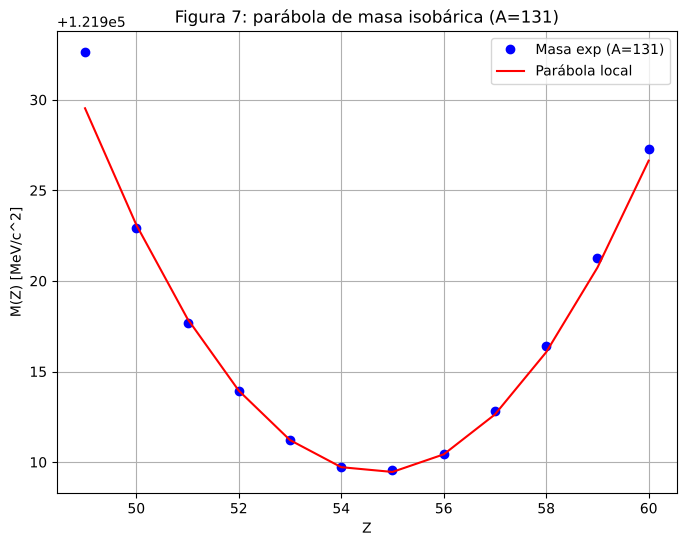

In [7]:
def M_parabola(Z):
    """Masa nuclear predicha por la parábola local ajustada, en MeV/c^2."""
    return alpha_loc + beta_loc * Z + gamma_loc * Z**2


Z_all = df_A131["Z"].values
M_exp_all = df_A131["mass"].values

Z_min, Z_max = Z_all.min(), Z_all.max()
Z_rango = np.arange(Z_min, Z_max + 1)
M_teorica = M_parabola(Z_rango)

plt.figure(figsize=(8, 6))
plt.plot(Z_all, M_exp_all, "bo", label="Masa exp (A=131)")
plt.plot(Z_rango, M_teorica, "r-", label="Parábola local")
plt.xlabel("Z")
plt.ylabel("M(Z) [MeV/c^2]")
plt.title("Figura 7: parábola de masa isobárica (A=131)")
plt.legend()
plt.grid(True)
plt.show()

**Figura 7**: los puntos azules corresponden a la masa experimental para cada $Z$ con $A=131$, y la curva roja al ajuste parabólico local. La curva ajustada describe razonablemente la variación de la masa con $Z$ para los isóbaros de $A = 131$.

---

## 5. Cálculo de $Q_\beta$ y Comparación con Datos

La desintegración $\beta^-$ convierte un neutrón del núcleo en un protón, con emisión de un electrón y un antineutrino: $(Z,A) \to (Z+1,A) + e^- + \bar{\nu}_e$. Como las masas $M(Z,A)$ empleadas en este trabajo son masas nucleares, sin los electrones atómicos (Sección 4), la energía liberada en la transición es

$$
Q_\beta = M(Z,A)c^2 - M(Z+1,A)c^2 - m_e c^2,
$$

donde se desprecia la masa del antineutrino. $Q_\beta$ es la energía cinética total que se reparten el electrón, el antineutrino y el núcleo hijo; la parte que se lleva el núcleo por retroceso es muy pequeña, pero está incluida en $Q_\beta$. Se calculan tanto la versión teórica, con la parábola ajustada, como la experimental, con las masas obtenidas directamente de los datos, para todos los isóbaros de $A = 131$ disponibles.

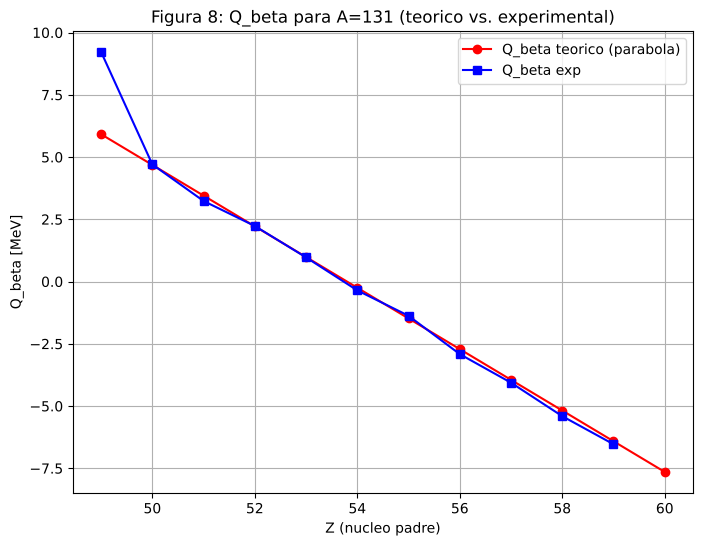

Comparacion numerica Q_beta (teo vs exp) para A=131:
Z=49: Q_teo=5.917 MeV, Q_exp=9.222 MeV
Z=50: Q_teo=4.684 MeV, Q_exp=4.704 MeV
Z=51: Q_teo=3.451 MeV, Q_exp=3.235 MeV
Z=52: Q_teo=2.218 MeV, Q_exp=2.232 MeV
Z=53: Q_teo=0.985 MeV, Q_exp=0.971 MeV
Z=54: Q_teo=-0.248 MeV, Q_exp=-0.355 MeV
Z=55: Q_teo=-1.481 MeV, Q_exp=-1.375 MeV
Z=56: Q_teo=-2.714 MeV, Q_exp=-2.915 MeV
Z=57: Q_teo=-3.947 MeV, Q_exp=-4.062 MeV
Z=58: Q_teo=-5.180 MeV, Q_exp=-5.407 MeV
Z=59: Q_teo=-6.413 MeV, Q_exp=-6.532 MeV
Z=60: Q_teo=-7.646 MeV, sin datos exp


In [8]:
def Qbeta_teorico(Z):
    """Q_beta teórico (MeV) para la transición (Z, A=131) -> (Z+1, A=131).

    Se calcula como la diferencia de masas nucleares predichas por la
    parábola local, restando la masa en reposo del electrón emitido en la
    desintegración beta menos (n -> p + e- + antineutrino):
    Q_beta(Z) = M_parabola(Z) - M_parabola(Z+1) - m_e*c^2.
    """
    return M_parabola(Z) - M_parabola(Z + 1) - m_e


# Serie indexada por Z para obtener la masa experimental de cualquier
# isobaro de A=131 sin necesidad de filtrar el DataFrame en un bucle.
masa_por_Z = df_A131.set_index("Z")["mass"].sort_index()
Z_sorted = masa_por_Z.index.values

Q_teo = Qbeta_teorico(Z_sorted)

# Q_beta experimental: diferencia de masas nucleares entre Z y Z+1, menos
# la masa del electron emitido (ver Qbeta_teorico). Cuando Z+1 no esta en
# la tabla, reindex produce NaN y ese punto se descarta.
masa_siguiente = masa_por_Z.reindex(Z_sorted + 1).values
Q_exp = masa_por_Z.values - masa_siguiente - m_e
hay_dato_exp = ~np.isnan(Q_exp)

plt.figure(figsize=(8, 6))
plt.plot(Z_sorted, Q_teo, "ro-", label="Q_beta teorico (parabola)")
plt.plot(Z_sorted[hay_dato_exp], Q_exp[hay_dato_exp], "bs-", label="Q_beta exp")
plt.xlabel("Z (nucleo padre)")
plt.ylabel("Q_beta [MeV]")
plt.title("Figura 8: Q_beta para A=131 (teorico vs. experimental)")
plt.legend()
plt.grid(True)
plt.show()

print("Comparacion numerica Q_beta (teo vs exp) para A=131:")
for z, qt, qe, tiene_exp in zip(Z_sorted, Q_teo, Q_exp, hay_dato_exp):
    if tiene_exp:
        print(f"Z={z}: Q_teo={qt:.3f} MeV, Q_exp={qe:.3f} MeV")
    else:
        print(f"Z={z}: Q_teo={qt:.3f} MeV, sin datos exp")

**Figura 8**: comparación entre los valores de $Q_\beta$ teóricos (línea roja) y experimentales (línea azul). Para $Z \geq 50$ la parábola local reproduce los valores experimentales con diferencias de a lo sumo 0.23 MeV; en $Z = 49$, en cambio, el valor experimental (9.22 MeV) supera en 3.3 MeV al de la parábola.

---

## 6. Núcleo Más Estable para A = 131

Para la parábola $M(Z) = \alpha + \beta Z + \gamma Z^2$, el mínimo de la masa nuclear se obtiene cuando

$$
\frac{dM}{dZ} = 0 \quad \Rightarrow \quad \beta + 2\,\gamma\,Z = 0 \quad \Rightarrow \quad
Z_\mathrm{i} = -\frac{\beta}{2\,\gamma}.
$$

La estabilidad frente a las desintegraciones $\beta$, sin embargo, la deciden las masas atómicas: despreciando las energías de enlace de los electrones, $Q_{\beta^-} = [M_{\text{at}}(Z) - M_{\text{at}}(Z+1)]\,c^2$ y $Q_{\text{CE}} = [M_{\text{at}}(Z) - M_{\text{at}}(Z-1)]\,c^2$ para la captura electrónica (Krane, 1988). El isóbaro estable es, por tanto, el de menor masa atómica, $M_{\text{at}}(Z) \approx M(Z) + Z\,m_e$, cuyo mínimo está en

$$
Z_\mathrm{A} = -\frac{\beta + m_e c^2}{2\,\gamma} = Z_\mathrm{i} - \frac{m_e c^2}{2\,\gamma}.
$$

In [9]:
Z_i = -beta_loc / (2 * gamma_loc)            # mínimo de la masa nuclear
Z_A = -(beta_loc + m_e) / (2 * gamma_loc)    # mínimo de la masa atómica
print(f"Mínimo de la masa nuclear según la parábola local: Z_i = {Z_i:.3f}")
print(f"Mínimo de la masa atómica según la parábola local: Z_A = {Z_A:.3f}")

Mínimo de la masa nuclear según la parábola local: Z_i = 54.713
Mínimo de la masa atómica según la parábola local: Z_A = 54.299


Ninguno de los dos valores es entero. El isóbaro estable es el de número atómico entero más cercano a $Z_\mathrm{A}$, $Z = 54$ ($^{131}\mathrm{Xe}$), que es en efecto el único isóbaro estable de $A = 131$. La diferencia entre $Z_\mathrm{i}$ y $Z_\mathrm{A}$, $m_e c^2/(2\gamma) \approx 0.41$, muestra que usar la masa nuclear en lugar de la atómica desplaza apreciablemente el mínimo, porque la curvatura de la parábola es pequeña frente a la masa del electrón.

---

## 7. Predicción de $Q_\beta$ para $^{131}\mathrm{Sb} \to {}^{131}\mathrm{Te}$ y $^{131}\mathrm{La} \to {}^{131}\mathrm{Ce}$

Se calculan específicamente:

- $Q_\beta(^{131}\mathrm{Sb} \to {}^{131}\mathrm{Te})$, con $Z = 51 \to 52$.
- $Q_\beta(^{131}\mathrm{La} \to {}^{131}\mathrm{Ce})$, con $Z = 57 \to 58$.

Los resultados se comparan con los valores experimentales disponibles.

In [10]:
def Qbeta_experimental(Z):
    """Q_beta experimental (MeV) para (Z, A=131) -> (Z+1, A=131).

    Igual que Qbeta_teorico, pero usando las masas nucleares obtenidas
    directamente de los datos en lugar de la parabola ajustada. Devuelve
    None si alguna de las dos masas no esta disponible en la tabla.
    """
    if Z in masa_por_Z.index and (Z + 1) in masa_por_Z.index:
        return masa_por_Z.loc[Z] - masa_por_Z.loc[Z + 1] - m_e
    return None


Z_Sb, Z_La = 51, 57

Q_Sb_teo = Qbeta_teorico(Z_Sb)
Q_La_teo = Qbeta_teorico(Z_La)
print(f"Prediccion Q_beta(131Sb->131Te) (teorico) = {Q_Sb_teo:.3f} MeV")
print(f"Prediccion Q_beta(131La->131Ce) (teorico) = {Q_La_teo:.3f} MeV")

Q_Sb_exp = Qbeta_experimental(Z_Sb)
Q_La_exp = Qbeta_experimental(Z_La)

print(f"Q_beta(131Sb->131Te) exp = {Q_Sb_exp:.3f} MeV" if Q_Sb_exp is not None
      else "No hay datos experimentales para 131Sb->131Te")
print(f"Q_beta(131La->131Ce) exp = {Q_La_exp:.3f} MeV" if Q_La_exp is not None
      else "No hay datos experimentales para 131La->131Ce")


Prediccion Q_beta(131Sb->131Te) (teorico) = 3.451 MeV
Prediccion Q_beta(131La->131Ce) (teorico) = -3.947 MeV
Q_beta(131Sb->131Te) exp = 3.235 MeV
Q_beta(131La->131Ce) exp = -4.062 MeV


---

## 8. Ajuste Directo de $Q_\beta$ Experimental y Búsqueda de $Z_p$

Si la masa sigue una parábola en $Z$, el valor $Q$ de la transición $Z \to Z+1$ es una función lineal de $Z$:

$$
Q_\beta(Z) = M(Z) - M(Z+1) - m_e c^2 = -\beta - \gamma\,(2Z + 1) - m_e c^2,
$$

con pendiente $-2\gamma$. Por eso se ajusta por mínimos cuadrados una recta a los valores experimentales de $Q_\beta$ y se determina $Z_p$, el número atómico del núcleo padre para el que $Q_\beta(Z_p) = 0$. El punto de $Z = 49$ ($^{131}\mathrm{In} \to {}^{131}\mathrm{Sn}$) se excluye del ajuste porque refleja el cierre de capa en $Z = 50$, que ninguna parábola describe (sección 8.1).

Como $Z_p$ corresponde al núcleo padre de una transición $Z \to Z+1$, el valor comparable con los mínimos de la sección 6 es el punto medio de la transición, $Z_p + 1/2$, que para una parábola exacta coincide con $Z_\mathrm{A}$.

In [11]:
# Valores experimentales de Q_beta (sección 5); se excluye Z = 49 del ajuste
Z_q = Z_sorted[hay_dato_exp].astype(float)
Q_q = Q_exp[hay_dato_exp]
en_ajuste = Z_q >= 50

(pendiente_Q, ordenada_Q), cov_Q = np.polyfit(Z_q[en_ajuste], Q_q[en_ajuste], deg=1, cov=True)
Z_p = -ordenada_Q / pendiente_Q
jacobiano = np.array([ordenada_Q / pendiente_Q**2, -1.0 / pendiente_Q])
sigma_Z_p = np.sqrt(jacobiano @ cov_Q @ jacobiano)

print(f"Pendiente = {pendiente_Q:.4f} MeV (la parábola local predice -2*gamma = {-2 * gamma_loc:.4f} MeV)")
print(f"Ordenada  = {ordenada_Q:.3f} MeV")
print(f"Z_p = {Z_p:.3f} +/- {sigma_Z_p:.3f}  (Q_beta = 0)")

Pendiente = -1.2471 MeV (la parábola local predice -2*gamma = -1.2330 MeV)
Ordenada  = 67.016 MeV
Z_p = 53.738 +/- 0.029  (Q_beta = 0)


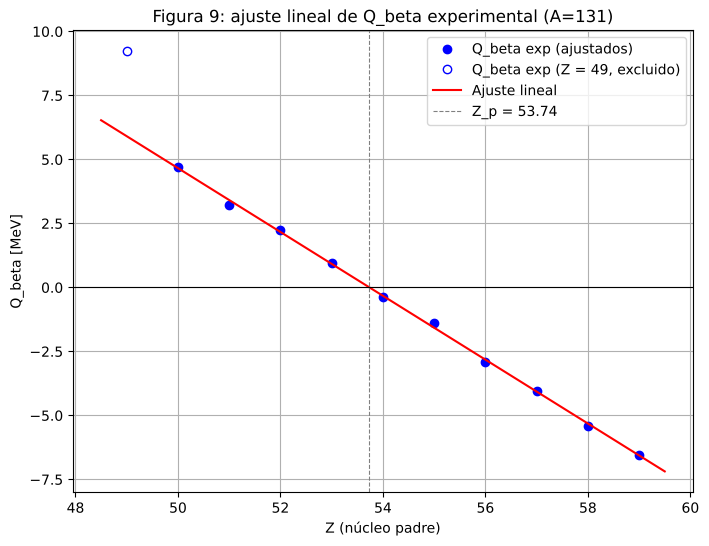

In [12]:
Z_recta = np.linspace(48.5, 59.5, 200)
plt.figure(figsize=(8, 6))
plt.plot(Z_q[en_ajuste], Q_q[en_ajuste], "bo", label="Q_beta exp (ajustados)")
plt.plot(Z_q[~en_ajuste], Q_q[~en_ajuste], "bo", mfc="none", label="Q_beta exp (Z = 49, excluido)")
plt.plot(Z_recta, pendiente_Q * Z_recta + ordenada_Q, "r-", label="Ajuste lineal")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(Z_p, color="gray", linestyle="--", linewidth=0.8, label=f"Z_p = {Z_p:.2f}")
plt.xlabel("Z (núcleo padre)")
plt.ylabel("Q_beta [MeV]")
plt.title("Figura 9: ajuste lineal de Q_beta experimental (A=131)")
plt.legend()
plt.grid(True)
plt.show()

**Figura 9**: valores experimentales de $Q_\beta$ (puntos azules) y recta ajustada por mínimos cuadrados (línea roja). El punto vacío, $Z = 49$, se excluye del ajuste. La línea discontinua marca $Z_p$, donde $Q_\beta = 0$.

In [13]:
print("Comparación de los puntos de estabilidad:")
print(f"Z_i         (mínimo de la masa nuclear)  = {Z_i:.3f}")
print(f"Z_A         (mínimo de la masa atómica)  = {Z_A:.3f}")
print(f"Z_p + 1/2   (ajuste directo de Q_beta)   = {Z_p + 0.5:.3f} +/- {sigma_Z_p:.3f}")
print(f"Diferencia |Z_p + 1/2 - Z_A| = {abs(Z_p + 0.5 - Z_A):.3f}")

Comparación de los puntos de estabilidad:
Z_i         (mínimo de la masa nuclear)  = 54.713
Z_A         (mínimo de la masa atómica)  = 54.299
Z_p + 1/2   (ajuste directo de Q_beta)   = 54.238 +/- 0.029
Diferencia |Z_p + 1/2 - Z_A| = 0.061


### 8.1. Análisis Adicional de los Resultados

**Discrepancia en $Z = 49$.** El valor experimental de $Q_\beta$ para $^{131}\mathrm{In} \to {}^{131}\mathrm{Sn}$ es 9.22 MeV, 3.3 MeV por encima del de la parábola. No se trata de una simple imprecisión de la extrapolación: $^{131}\mathrm{In}$ ($Z = 49$, $N = 82$) y $^{131}\mathrm{Sn}$ ($Z = 50$, $N = 81$) son vecinos inmediatos del núcleo doblemente mágico $^{132}\mathrm{Sn}$. Como muestran las Figuras 5 y 6, la energía de enlace de los núcleos con capas cerradas excede en varios MeV la predicción de la gota líquida, y ese exceso cambia bruscamente al cruzar $Z = 50$. Una parábola determinada con $Z = 52$, 54 y 56, todos por encima del cierre de capa, no puede anticipar ese cambio; para $Z \geq 50$, en cambio, describe los valores de $Q_\beta$ con diferencias de a lo sumo 0.23 MeV.

**Término de apareamiento.** Para $A$ impar, cada isóbaro tiene un número par de protones y uno impar de neutrones, o al revés, de modo que el término de apareamiento es nulo para todos ellos y los isóbaros de $A = 131$ se describen con una sola parábola. Para $A$ par, en cambio, los isóbaros par-par e impar-impar se reparten en dos parábolas separadas por $2a_5/A^{1/2}$, y el término de apareamiento sí es esencial.

**Interpretación de $Q_\beta$ negativo.** Los valores negativos de $Q_\beta$, a partir de $Z = 54$, indican que la desintegración $\beta^-$ no es energéticamente posible. Para $^{131}\mathrm{Xe}$ ($Z = 54$) esto significa estabilidad: tampoco puede desintegrarse hacia $Z = 53$, porque $Q_\beta(53) > 0$. Para $Z \geq 55$, el proceso favorable es el inverso: como $Q_{\text{CE}}(Z) = -Q_\beta(Z-1)$ en términos de masas atómicas, esos núcleos se desintegran hacia $Z$ menores por captura electrónica o, cuando la diferencia de masas lo permite, por emisión $\beta^+$, hasta llegar a $^{131}\mathrm{Xe}$.

**Puntos de estabilidad.** El ajuste directo da $Z_p + 1/2 = 54.24 \pm 0.03$, a 0.06 del mínimo de la masa atómica $Z_\mathrm{A} = 54.30$ de la parábola local, y la pendiente ajustada ($-1.247$ MeV) coincide con la que predice la parábola ($-2\gamma = -1.233$ MeV) dentro del 1.2 %. La diferencia aparente entre $Z_p \approx 53.7$ y $Z_\mathrm{i} \approx 54.7$ se debe casi por completo a que se comparan magnitudes definidas de manera distinta: medio número atómico por definir $Z_p$ sobre el núcleo padre, y 0.41 por usar la masa nuclear en lugar de la atómica.

---

## 9. Conclusiones

1. **Modelo de gota líquida (global).** Reproduce la tendencia general de la energía de enlace por nucleón y permite descomponer los aportes de volumen, superficie, Coulomb y asimetría; el término de Coulomb es el responsable del máximo de la curva. Con los coeficientes ajustados y el término de apareamiento, el residuo cuadrático medio es de 3.0 MeV para $A \geq 16$, y los residuos restantes se concentran en los números mágicos 28, 50, 82 y 126, una manifestación directa de la estructura de capas que el modelo no incluye.

2. **Ajuste local para A = 131.** La parábola obtenida a partir de $^{131}\mathrm{Te}$, $^{131}\mathrm{Xe}$ y $^{131}\mathrm{Ba}$ describe la masa de los isóbaros con $Z \geq 50$ y sus valores de $Q_\beta$ con diferencias de a lo sumo 0.23 MeV. Falla en $Z = 49$, junto al cierre de capa de $^{132}\mathrm{Sn}$, donde el valor experimental supera en 3.3 MeV al predicho.

3. **Isóbaro estable.** El mínimo de la masa atómica de la parábola, $Z_\mathrm{A} = 54.30$, y el punto en que se anula el $Q_\beta$ experimental, $Z_p + 1/2 = 54.24 \pm 0.03$, coinciden e identifican a $^{131}\mathrm{Xe}$ como el isóbaro estable. Para esta comparación es esencial usar masas atómicas: el mínimo de la masa nuclear, $Z_\mathrm{i} = 54.71$, está desplazado 0.41 unidades.

4. **Predicción específica de $Q_\beta$.** Para la transición $^{131}\mathrm{Sb} \to {}^{131}\mathrm{Te}$, la predicción de la parábola es de 3.45 MeV, frente a un valor experimental de 3.24 MeV. Para $^{131}\mathrm{La} \to {}^{131}\mathrm{Ce}$, la predicción es de $-3.95$ MeV, consistente con el valor experimental de $-4.06$ MeV; el signo negativo indica que el proceso que ocurre es el inverso, la desintegración de $^{131}\mathrm{Ce}$ en $^{131}\mathrm{La}$ por captura electrónica o emisión $\beta^+$.

5. **Perspectivas.** Para describir los isóbaros próximos a capas cerradas se requieren correcciones de capa, que podrían incorporarse a partir de los residuos de las Figuras 5 y 6. El ajuste local mejoraría con una regresión por mínimos cuadrados sobre todos los isóbaros con $Z \geq 50$, en lugar de una interpolación exacta por tres puntos.

---

## Referencias

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, *9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Krane, K. S. (1988). *Introductory nuclear physics*. John Wiley & Sons.

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a

Mohr, P. J., Newell, D. B., & Taylor, B. N. (2016). CODATA recommended values of the fundamental physical constants: 2014. *Reviews of Modern Physics*, *88*(3), 035009. https://doi.org/10.1103/RevModPhys.88.035009

Wang, M., Huang, W. J., Kondev, F. G., Audi, G., & Naimi, S. (2021). The AME 2020 atomic mass evaluation (II). Tables, graphs and references. *Chinese Physics C*, *45*(3), 030003. https://doi.org/10.1088/1674-1137/abddaf